# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.




### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [12]:
data = pd.read_csv(r'C:\Users\mites\Desktop\Ironhack\Week 2\Day 4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv')

In [13]:
df = data.copy()

In [14]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [15]:
cat = df.select_dtypes(exclude="number")

In [16]:
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


In [ ]:

top_categories = df['category'].value_counts().head(5)
print(top_categories)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [18]:
top_categories=df['category'].value_counts().head(5).reset_index()

In [19]:
top_categories.columns= ['category', 'num_listings']

In [20]:
top_categories

,category,num_listings
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


C:\Users\mites\AppData\Local\Temp\ipykernel_15276\2664593368.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


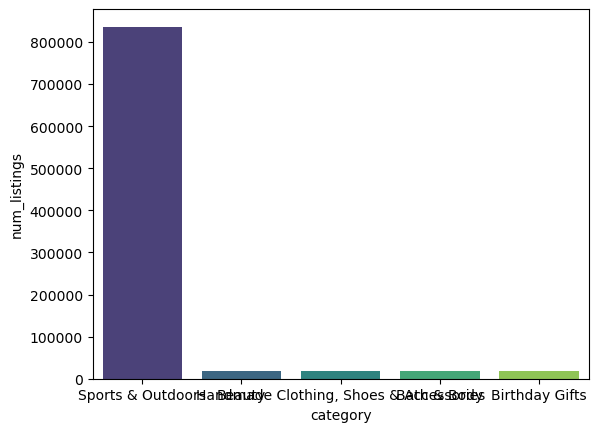

In [21]:
sns.barplot(
    x="category",
    y='num_listings',
    data=top_categories,
    palette='viridis',
)
plt.show()

In [22]:
frequency_table = cat.category.value_counts().head(5)

In [23]:
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

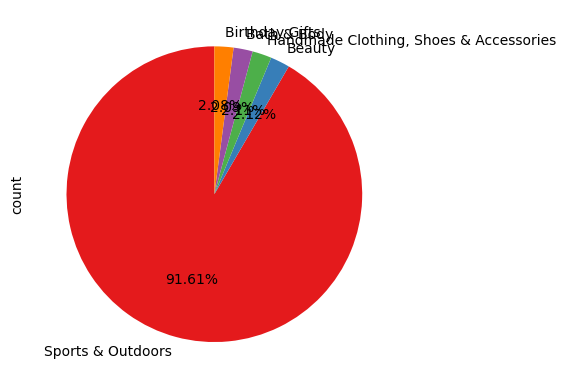

In [24]:
frequency_table.plot.pie(autopct='%1.2f%%' ,startangle=90, colors=sns.color_palette('Set1'))
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [25]:
num = df.select_dtypes(include="number") 

In [26]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [27]:
num.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [28]:
round(float(num["price"].mean()), 2)

89.24

In [29]:
round(float(num["price"].median()), 2)

19.09

In [30]:
round(float(num["price"].mode()), 2)

C:\Users\mites\AppData\Local\Temp\ipykernel_15276\3922291261.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  round(float(num["price"].mode()), 2)


9.99

In [31]:
num["price"].mode()

0    9.99
Name: price, dtype: float64

In [32]:
average_price = num['price'].mean()
print(f"Average price:", average_price)


Average price: 89.24380943923663


In [33]:
mode_price = num['price'].mode()[0]
print(f"Most common price (mode):", mode_price)


Most common price (mode): 9.99



2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [34]:
variance = df['price'].var()
std_dev = df['price'].std()
range_value = df['price'].max() - df['price'].min()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("Range:", range_value)
print("Interquartile Range (IQR):", iqr)


Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


In [35]:
#Variance (~119,445) and standard deviation (~345.6) are quite large, indicating that prices are widely spread out from the mean.

#Range (100,000) is very large, meaning product prices span from very low to very high values.

#However, the Interquartile Range (36) is relatively small compared to the range and standard deviation, showing that the middle 50% of products are priced within a narrower band.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


In [36]:
import seaborn as sns
import matplotlib.pyplot as plt




<function matplotlib.pyplot.show(close=None, block=None)>

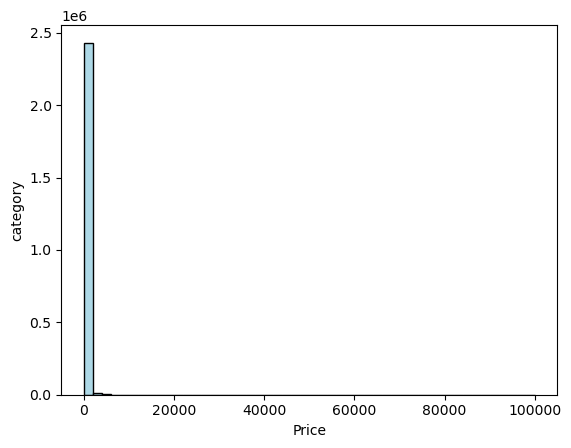

In [45]:
import matplotlib.pyplot as plt


plt.hist(df['price'], bins=50, color='lightblue', edgecolor='black')
plt.xlabel('Price')
plt.ylabel('category')
plt.show



In [ ]:
num["price"].skew()

np.float64(27.492977566280338)

In [ ]:
round(float(num["price"].skew()), 2)

27.49

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [ ]:
round(float(num["stars"].median()))

0

In [ ]:
round(float(num["stars"].mean()))

2

In [ ]:
# Select all rows where rating is NOT zero, all columns
df_filtered = df.loc[df['stars'] != 0, :]


In [ ]:
mean_filtered = df_filtered['stars'].mean()
median_filtered = df_filtered['stars'].median()
mode_filtered = df_filtered['stars'].mode()[0]

print(f"Mean rating (filtered):", mean_filtered)
print(f"Median rating (filtered):",  median_filtered)
print(f"Mode rating (filtered):", mode_filtered)


Mean rating (filtered): 4.31916076222691
Median rating (filtered): 4.4
Mode rating (filtered): 4.5


In [ ]:
# A Customer rating between 4.2 - 4.7 stars indicates favourable reviews. 
# As we can see the average rating is 4.3 stars, which is considered pretty good. 

C:\Users\mites\AppData\Local\Temp\ipykernel_15196\4217782052.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


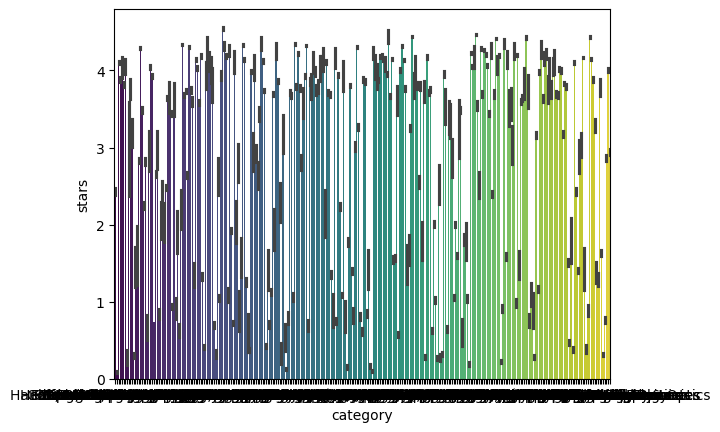

In [ ]:
sns.barplot(
    x="category",
    y='stars',
    data=df,
    palette='viridis',
    plt.barh
)
plt.show()

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [ ]:
variance = df['stars'].var()
std_dev = df['stars'].std()
range_value = df['stars'].max() - df['stars'].min()
iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("Range:", range_value)
print("Interquartile Range (IQR):", iqr)

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
Range: 5.0
Interquartile Range (IQR): 4.4


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?


In [ ]:
round(float(num["stars"].skew()), 2)

0.08

In [ ]:
skewness = df['stars'].skew()
kurtosis = df['stars'].kurt()

print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurtosis}")


Skewness: 0.08120735761080985
Kurtosis: -1.9260061280432985


In [ ]:
#The distribution of ratings is not perfectly normal but close to symmetric.

#Skewness = 0.0812, which is very close to zero. This implies the ratings are nearly symmetric without significant leaning toward higher or lower values. There is a very slight positive skew, meaning a very slight tendency toward lower ratings but effectively balanced.
#Kurtosis = -1.926, which is negative and quite far from zero. This indicates athat the distribution—flatter and less peaked than a normal distribution. The ratings are spread more evenly with fewer extreme outliers or sharp peaks.


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 


In [ ]:
import matplotlib.pyplot as plt

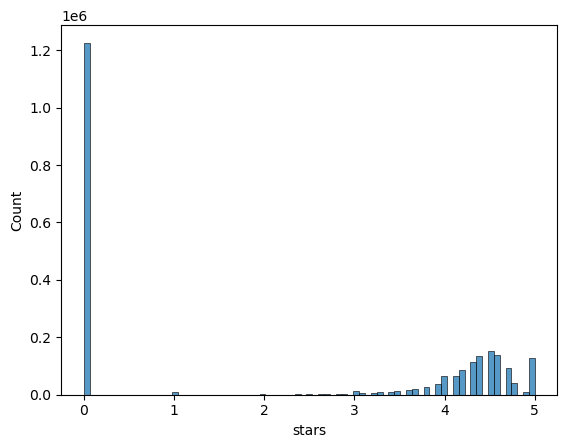

In [ ]:
sns.histplot(df.stars, bins="auto")
plt.show()

In [ ]:
#Yes, the rating '0' is very common 